In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Output Explanation

In [ ]:
df = pd.read_csv("Spotify.csv")

In [ ]:
df.shape


(2017, 16)

In [ ]:
df.columns

Index(['acousticness', 'danceability', 'duration_ms', 'energy',
       'instrumentalness', 'key', 'liveness', 'loudness', 'mode',
       'speechiness', 'tempo', 'time_signature', 'valence', 'target',
       'song_title', 'artist'],
      dtype='object')

In [ ]:
df.dtypes

,0
acousticness,float64
danceability,float64
duration_ms,int64
energy,float64
instrumentalness,float64
key,int64
liveness,float64
loudness,float64
mode,int64
speechiness,float64


### Data Types

The dataset contains integer, float and object data types. Numerical columns are stored in numeric formats, while song_title and artist are stored as text. No data type conversion is required.

In [ ]:
df.head()

,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target,song_title,artist
0,0.0102,0.833,204600,0.434,0.021900,2,0.1650,-8.795,1,0.4310,150.062,4.0,0.286,1,Mask Off,Future
1,0.1990,0.743,326933,0.359,0.006110,1,0.1370,-10.401,1,0.0794,160.083,4.0,0.588,1,Redbone,Childish Gambino
2,0.0344,0.838,185707,0.412,0.000234,2,0.1590,-7.148,1,0.2890,75.044,4.0,0.173,1,Xanny Family,Future
3,0.6040,0.494,199413,0.338,0.510000,5,0.0922,-15.236,1,0.0261,86.468,4.0,0.230,1,Master Of None,Beach House
4,0.1800,0.678,392893,0.561,0.512000,5,0.4390,-11.648,0,0.0694,174.004,4.0,0.904,1,Parallel Lines,Junior Boys


In [ ]:
df.describe()

,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target
count,2017.000000,2017.000000,2.017000e+03,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000
mean,0.187590,0.618422,2.463062e+05,0.681577,0.133286,5.342588,0.190844,-7.085624,0.612295,0.092664,121.603272,3.968270,0.496815,0.505702
std,0.259989,0.161029,8.198181e+04,0.210273,0.273162,3.648240,0.155453,3.761684,0.487347,0.089931,26.685604,0.255853,0.247195,0.500091
min,0.000003,0.122000,1.604200e+04,0.014800,0.000000,0.000000,0.018800,-33.097000,0.000000,0.023100,47.859000,1.000000,0.034800,0.000000
25%,0.009630,0.514000,2.000150e+05,0.563000,0.000000,2.000000,0.092300,-8.394000,0.000000,0.037500,100.189000,4.000000,0.295000,0.000000
50%,0.063300,0.631000,2.292610e+05,0.715000,0.000076,6.000000,0.127000,-6.248000,1.000000,0.054900,121.427000,4.000000,0.492000,1.000000
75%,0.265000,0.738000,2.703330e+05,0.846000,0.054000,9.000000,0.247000,-4.746000,1.000000,0.108000,137.849000,4.000000,0.691000,1.000000
max,0.995000,0.984000,1.004627e+06,0.998000,0.976000,11.000000,0.969000,-0.307000,1.000000,0.816000,219.331000,5.000000,0.992000,1.000000


### Step 2: Research Questions

1. What is the distribution of song energy?
2. What is the distribution of danceability?
3. Which artists have the most songs?
4. What is the average song duration?
5. Is there a relationship between energy and danceability?
6. Does tempo affect danceability?
7. How does loudness vary with energy?
8. How does danceability compare between the two target groups?

Missing Values

In [ ]:
df.isnull().sum()

,0
acousticness,0
danceability,0
duration_ms,0
energy,0
instrumentalness,0
key,0
liveness,0
loudness,0
mode,0
speechiness,0


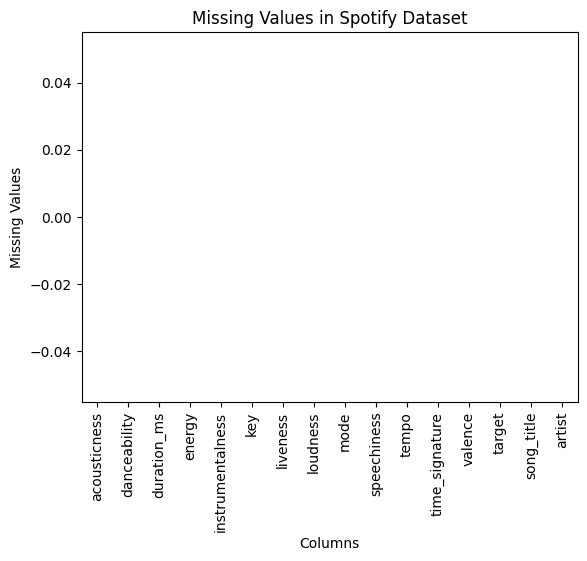

In [ ]:
df.isnull().sum().plot(kind="bar")
plt.title("Missing Values in Spotify Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.show()

Duplicated Values

In [ ]:
df.duplicated().sum()

np.int64(5)

### Repeated Rows

We checked the dataset for duplicate rows. The result was zero, which means there are no repeated rows. Therefore, no rows were removed.

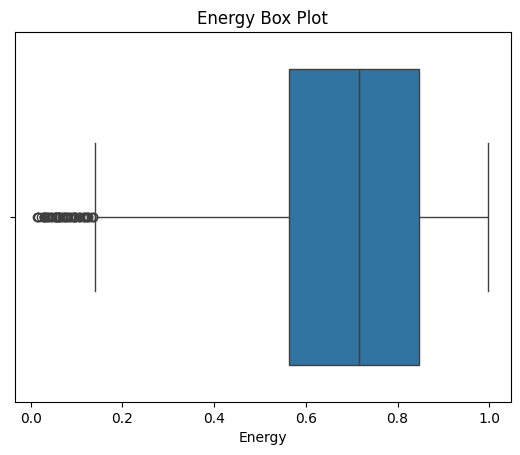

In [ ]:
sns.boxplot(x=df["energy"])
plt.title("Energy Box Plot")
plt.xlabel("Energy")
plt.show()


The box plot shows that most songs have energy values between 0.56 and 0.85. There are 54 outliers on the lower side, showing some songs have unusually low energy.

In [ ]:
q1 = df["energy"].quantile(0.25)
q3 = df["energy"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df["energy"] < lower) | (df["energy"] > upper)]
print("outliers:", len(outliers))

outliers: 54


The IQR method identified 54 outliers in the energy column. These values are kept because they may represent genuine differences in music.

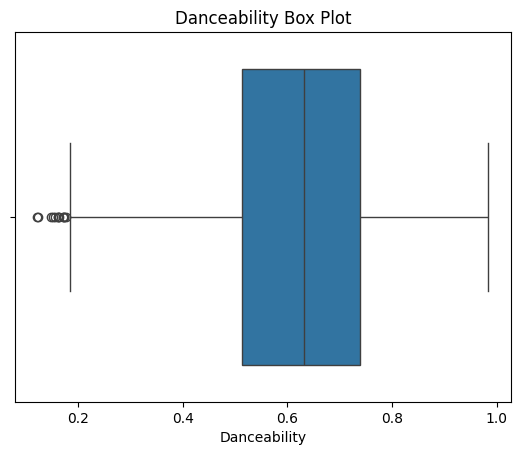

In [ ]:
sns.boxplot(x=df["danceability"])
plt.title("Danceability Box Plot")
plt.xlabel("Danceability")
plt.show()

The box plot shows 12 outliers in the danceability column. These values represent songs with unusually low danceability.

In [ ]:
q1 = df["danceability"].quantile(0.25)
q3 = df["danceability"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df["danceability"] < lower) | (df["danceability"] > upper)]

print("Outliers:", len(outliers))

Outliers: 12


The IQR method identified 12 outliers in the danceability column. These values are kept because they may represent genuine song characteristics.

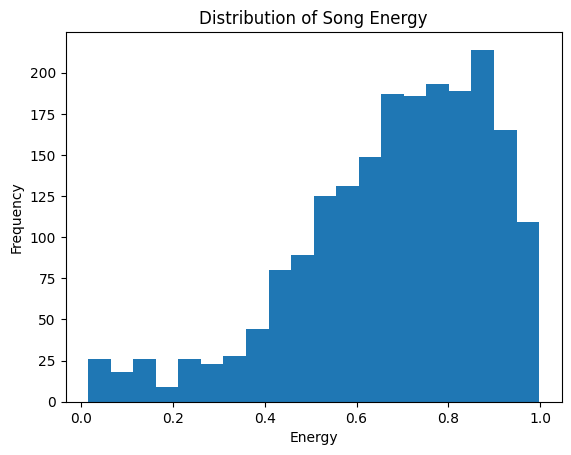

In [ ]:
plt.hist(df["energy"], bins=20)
plt.title("Distribution of Song Energy")
plt.xlabel("Energy")
plt.ylabel("Frequency")
plt.show()

The histogram shows that most songs have energy values between 0.6 and 0.9. Only a few songs have low energy values.

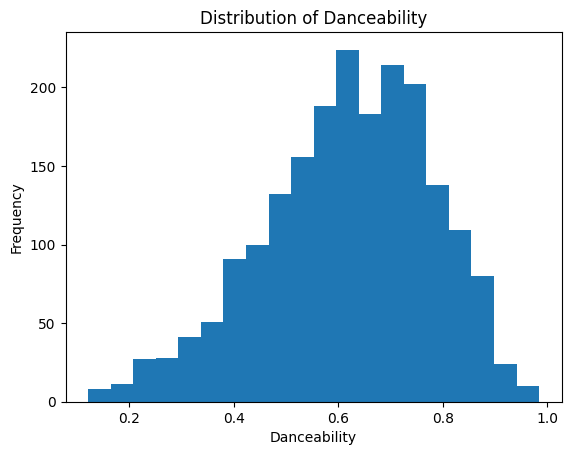

In [ ]:
plt.hist(df["danceability"], bins=20)
plt.title("Distribution of Danceability")
plt.xlabel("Danceability")
plt.ylabel("Frequency")
plt.show()

The histogram shows the distribution of danceability values. It helps us understand how danceable the songs are.

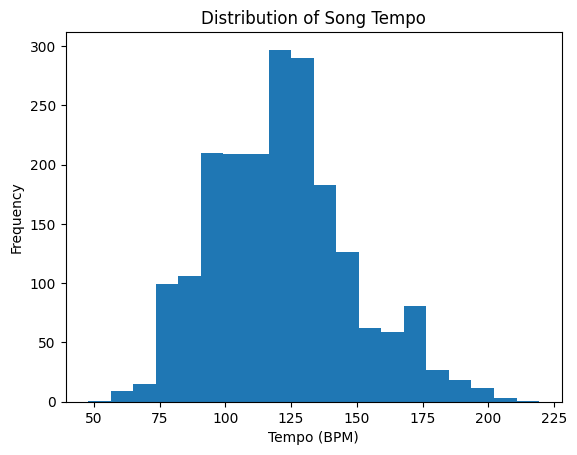

In [ ]:
plt.hist(df["tempo"], bins=20)
plt.title("Distribution of Song Tempo")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Frequency")
plt.show()

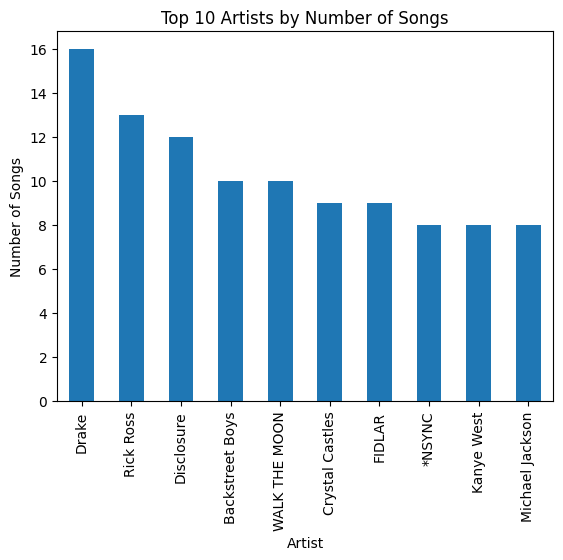

In [ ]:
df["artist"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Artists by Number of Songs")
plt.xlabel("Artist")
plt.ylabel("Number of Songs")
plt.show()

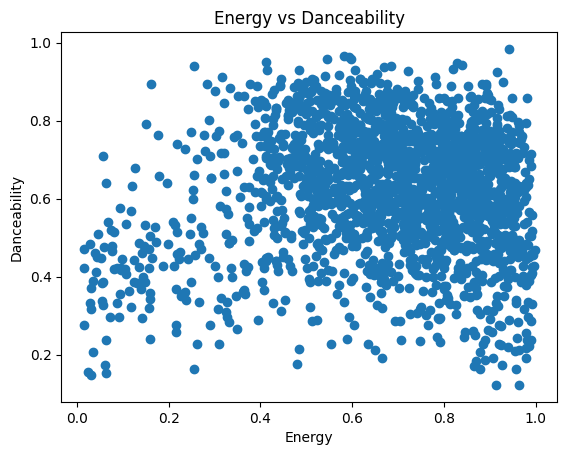

In [ ]:
plt.scatter(df["energy"], df["danceability"])
plt.title("Energy vs Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")
plt.show()

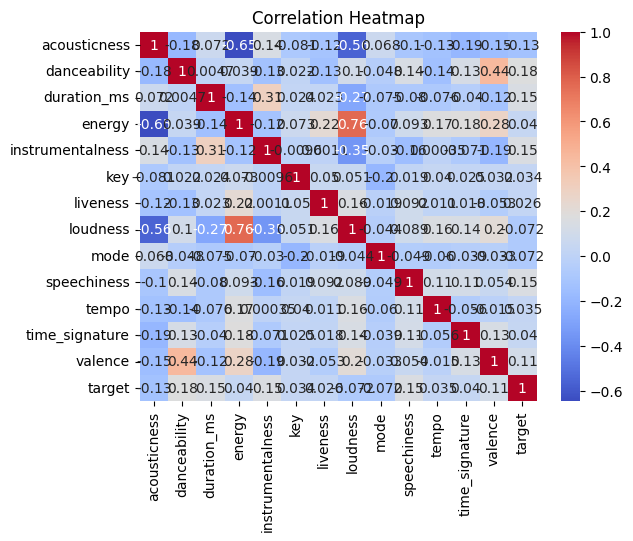

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

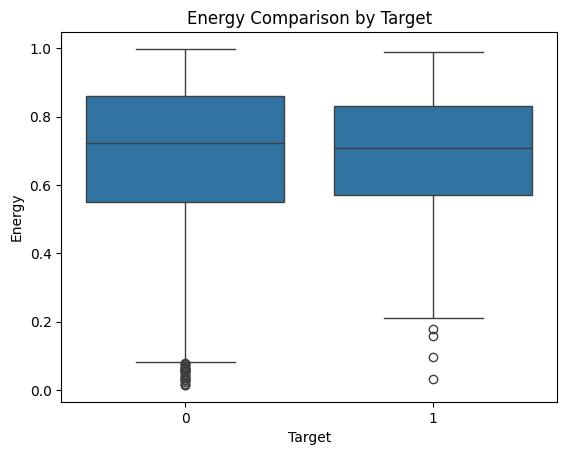

In [ ]:
sns.boxplot(x="target", y="energy", data=df)
plt.title("Energy Comparison by Target")
plt.xlabel("Target")
plt.ylabel("Energy")
plt.show()

Q1. What is the distribution of song energy?

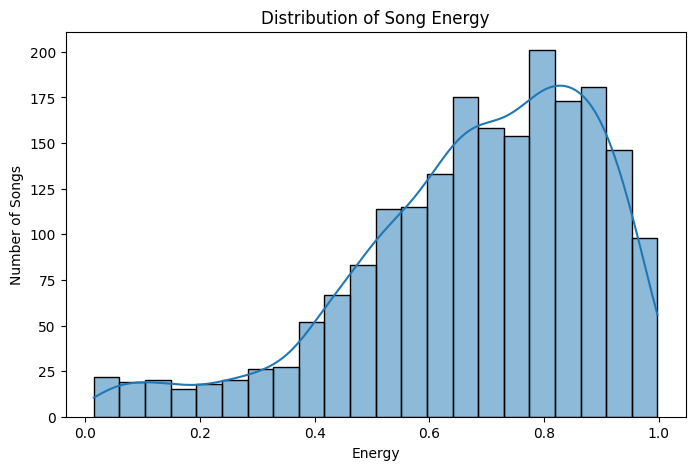

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["energy"], kde=True)
plt.title("Distribution of Song Energy")
plt.xlabel("Energy")
plt.ylabel("Number of Songs")
plt.show()

Most songs have energy values between 0.6 and 0.9. This shows that the dataset contains many high-energy songs.

Q2. What is the distribution of danceability?

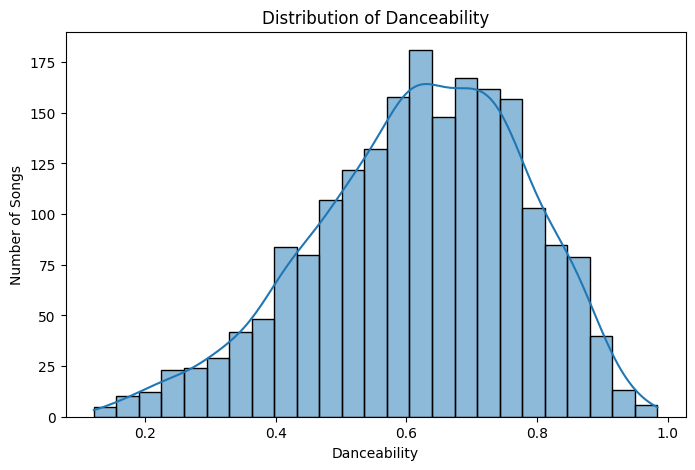

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["danceability"], kde=True)
plt.title("Distribution of Danceability")
plt.xlabel("Danceability")
plt.ylabel("Number of Songs")
plt.show()

The histogram shows the distribution of danceability among songs. Most songs have moderate to high danceability values.

Q3. Which artists have the most songs?

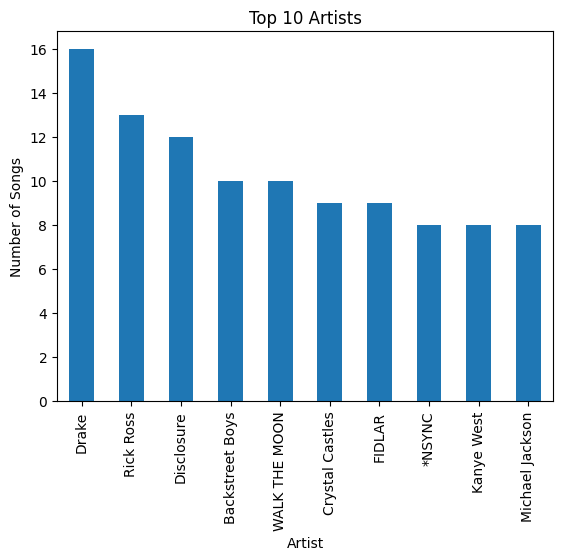

In [ ]:
df["artist"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Artists")
plt.xlabel("Artist")
plt.ylabel("Number of Songs")
plt.show()

The bar chart shows the top 10 artists with the highest number of songs in the dataset. It helps identify which artists appear most frequently.

Q4. What is the average song duration?

Average Duration: 4.10510328871261 minutes


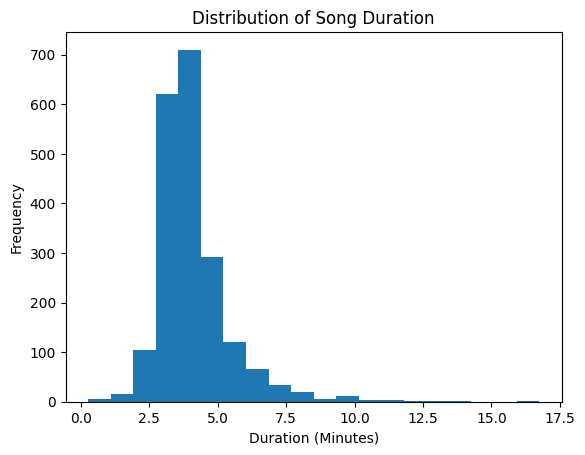

In [ ]:
print("Average Duration:", df["duration_ms"].mean() / 60000, "minutes")

plt.hist(df["duration_ms"] / 60000, bins=20)
plt.title("Distribution of Song Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Frequency")
plt.show()

The average song duration is shown by the calculation above. The histogram displays how song durations are distributed in the dataset.

Q5. Is there a relationship between energy and danceability?

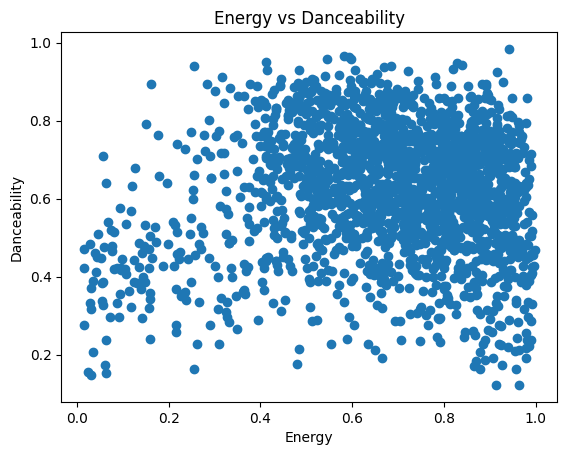

0.038556708956917686


In [ ]:
plt.scatter(df["energy"], df["danceability"])
plt.title("Energy vs Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")
plt.show()

print(df["energy"].corr(df["danceability"]))

The scatter plot shows the relationship between energy and danceability. It helps us understand whether songs with higher energy also have higher danceability.

Q6. Does tempo affect danceability?

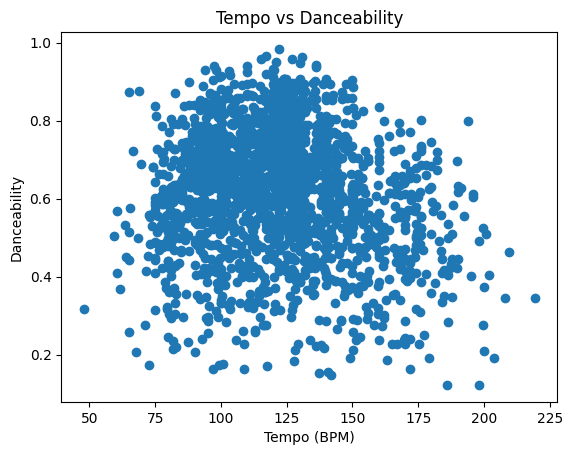

-0.14353833210284447


In [ ]:
plt.scatter(df["tempo"], df["danceability"])
plt.title("Tempo vs Danceability")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Danceability")
plt.show()

print(df["tempo"].corr(df["danceability"]))

The scatter plot shows the relationship between tempo and danceability. Correlation helps us understand whether faster songs tend to have higher or lower danceability. Correlation does not prove cause and effect.

Q7. How does loudness vary with energy?

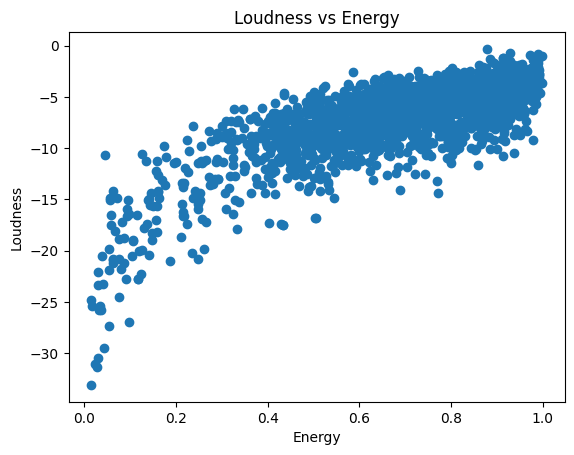

In [ ]:
plt.scatter(df["energy"], df["loudness"])
plt.title("Loudness vs Energy")
plt.xlabel("Energy")
plt.ylabel("Loudness")
plt.show()

The scatter plot shows how loudness changes with song energy. It helps us understand whether songs with higher energy also tend to have higher loudness.

Q8. How does danceability compare between the two target groups?

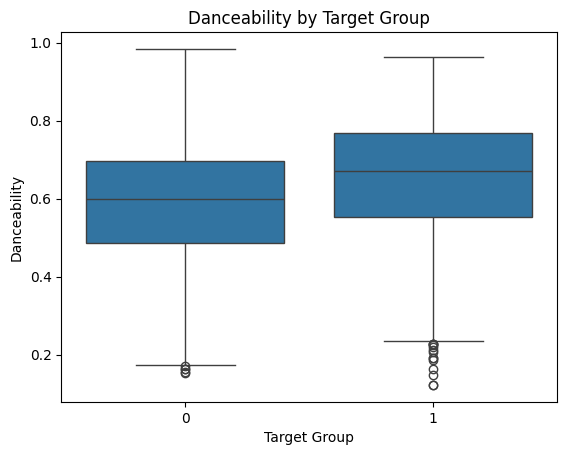

In [ ]:
sns.boxplot(x="target", y="danceability", data=df)
plt.title("Danceability by Target Group")
plt.xlabel("Target Group")
plt.ylabel("Danceability")
plt.show()

The box plot compares danceability between the two target groups (0 and 1). It helps us identify differences in danceability between these groups.

## Conclusion

### Main Findings

1. Most songs in the dataset have high energy values.
2. Many songs have moderate to high danceability.
3. Energy and danceability help us understand the musical characteristics of songs.

### Suggestion

Spotify can use song features such as energy, danceability and tempo to improve music recommendations for listeners.